# Did Oregon’s Medicaid lottery change emergency-department use?
### A focused causal-inference portfolio project

**Finding:** Being selected in the lottery increased the estimated probability of any recorded ED visit by **1.72 percentage points** (95% CI **0.56–2.88**), or about **17 additional people per 1,000**, over March 10, 2008–September 30, 2009. One alternative model gives nearly the same estimate.

**Why this matters:** Insurance access may change healthcare use. This project demonstrates how to use a randomized opportunity to apply for insurance to answer a narrow utilization question, while distinguishing statistical evidence from practical importance. This is a reanalysis of existing experimental data, not a new experiment.

## 1. Question and design

Among people in the study’s Portland-area ED catchment, what was the effect of **lottery selection** on the chance of any recorded visit to the 12 study hospitals?

Lottery selection offered the opportunity to apply for Medicaid; it did not guarantee coverage. The opportunity extended to household members, so comparisons must account for the number of household members on the lottery list. We estimate the **intention-to-treat (ITT)** effect of that opportunity, not an effect of enrollment.

The primary estimate averages household-size-specific contrasts over the study sample, adjusting for baseline ED use. Household-clustered uncertainty accounts for people sharing assignment. A common-slope model is the single sensitivity check. These choices were recorded in the supporting Stage 2 work before fitting the outcome model.

## 2. Load and verify the public-use data

Download the original archive from the [OHIE data page](https://www.nber.org/research/data/oregon-health-insurance-experiment-data). Set `OHIE_ZIP` to its local path or place `oregon_puf.zip` beside this notebook. Install `requirements.txt` and run cells in order. The ZIP is read directly; data are not redistributed with this case study. Aggregate results and the chart are written to the current folder.

Key fields: `person_id` links people; `household_id` identifies clusters; `treatment` is lottery selection; `numhh_list` is listed household size; `any_visit_pre_ed` is baseline any ED use; `any_visit_ed` is study-period any ED use.

In [1]:
from pathlib import Path
import hashlib
import io
import os
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from patsy import build_design_matrices, dmatrix

archive_path = Path(os.environ.get("OHIE_ZIP", "oregon_puf.zip"))
if not archive_path.is_file():
    raise FileNotFoundError(
        "Set OHIE_ZIP or place oregon_puf.zip beside this notebook."
    )
print("Archive SHA256:", hashlib.sha256(archive_path.read_bytes()).hexdigest())

with zipfile.ZipFile(archive_path) as archive:

    def read_source(name):
        member = f"OHIE_Public_Use_Files/OHIE_Data/oregonhie_{name}_vars.dta"
        return pd.read_stata(
            io.BytesIO(archive.read(member)), convert_categoricals=False
        )

    descriptive = read_source("descriptive")
    ed = read_source("ed")

for frame in [descriptive, ed]:
    assert frame.person_id.is_unique and frame.person_id.notna().all()
assert set(ed.person_id).issubset(set(descriptive.person_id))
assert len(descriptive) == 74922 and len(ed) == 24646
analysis = ed.merge(descriptive, on="person_id", how="left", validate="one_to_one")
key_fields = [
    "household_id",
    "treatment",
    "numhh_list",
    "any_visit_pre_ed",
    "any_visit_ed",
]
assert analysis[key_fields].notna().all().all()
assert analysis.sample_ed.eq(1).all()
assert analysis.groupby("household_id").treatment.nunique().max() == 1
for column in ["treatment", "any_visit_pre_ed", "any_visit_ed"]:
    assert analysis[column].isin([0, 1]).all()
print(
    f"Verified {len(analysis):,} people across {analysis.household_id.nunique():,} households."
)


Archive SHA256: 0426efe3c226ed39ce746322885cbf9bfabff26b759de282378ba1a0012f9e8a
Verified 24,646 people across 22,188 households.


The sample contains 9,626 selected people and 15,020 controls. People outside the ED file are outside the documented catchment; their missing records are not zero visits. Baseline any-use covers January 1, 2007–March 9, 2008. The study outcome uses a common calendar window, not equal follow-up after each person enrolls.

The source appendix documents 70 ZIP codes selected using study-hospital capture of ED-origin admissions. Public IDs allow verification of our merges; they do not let us reconstruct the original geographic selection or probabilistic clinical-record matching. Censored visit counts are excluded from the primary analysis.

## 3. Inspect baseline balance and raw rates

We check baseline characteristics with household-size adjustment, following the design rather than selecting controls based on p-values. Small observed differences are reassuring but do not prove randomization or absence of selection bias.

In [2]:
cluster_options = {
    "groups": analysis.household_id,
    "use_correction": True,
    "df_correction": True,
}


def fit_model(formula):
    return smf.ols(formula, data=analysis, missing="raise").fit(
        cov_type="cluster", cov_kwds=cluster_options, use_t=True
    )


baseline_fields = [
    "birthyear_list",
    "female_list",
    "english_list",
    "self_list",
    "first_day_list",
    "have_phone_list",
    "pobox_list",
    "any_visit_pre_ed",
]
balance_rows = []
for variable in baseline_fields:
    assert analysis[variable].notna().all()
    diagnostic = fit_model(f"{variable} ~ treatment + C(numhh_list)")
    arm_variances = analysis.groupby("treatment")[variable].var()
    pooled_sd = np.sqrt(arm_variances.mean())
    balance_rows.append(
        {
            "variable": variable,
            "adjusted_standardized_difference": diagnostic.params["treatment"]
            / pooled_sd,
        }
    )
balance = pd.DataFrame(balance_rows)
print(balance.round(3).to_string(index=False))
raw_rates = analysis.groupby("treatment").any_visit_ed.agg(people="size", rate="mean")
print("\nUnadjusted rates (descriptive only):")
print(raw_rates.to_string())
print("\nPeople by listed household size:")
print(pd.crosstab(analysis.numhh_list, analysis.treatment).to_string())


        variable  adjusted_standardized_difference
  birthyear_list                             0.008
     female_list                            -0.020
    english_list                             0.026
       self_list                             0.002
  first_day_list                             0.022
 have_phone_list                             0.008
      pobox_list                             0.006
any_visit_pre_ed                             0.010

Unadjusted rates (descriptive only):
           people      rate
treatment                  
0           15020  0.344873
1            9626  0.341367

People by listed household size:
treatment       0     1
numhh_list             
1           12888  6755
2            2126  2825
3               6    46


All eight absolute adjusted standardized differences are below 0.027. These diagnostics use raw pooled within-arm standard deviations as denominators.

Raw study-period rates are approximately **34.14% selected versus 34.49% unselected**. That raw contrast is not the design-adjusted estimate: selection probabilities differ with listed household size. The largest category has only six controls and 46 selected people; it remains in the target population with its small sample weight, and its separate contrast is imprecise.

## 4. Estimate the adjusted ITT

A linear probability model directly expresses changes in probability. The primary model includes household-size categories, selection-by-size interactions, and baseline any ED use. We predict each sample member under selection and nonselection and average the difference. A linear contrast carries the complete household-clustered covariance into the interval.

The model comparison is intentionally limited to one sensitivity check. No survey weights, enrollment conditioning, post-assignment exclusions, censored counts, or outcome-subtype searches are used.

In [3]:
primary_formula = "any_visit_ed ~ treatment * C(numhh_list) + any_visit_pre_ed"
comparison_formula = "any_visit_ed ~ treatment + C(numhh_list) + any_visit_pre_ed"
primary_model = fit_model(primary_formula)
comparison_model = fit_model(comparison_formula)

reference_design = dmatrix(
    primary_formula.split("~", 1)[1], analysis, return_type="dataframe"
)
assert list(reference_design.columns) == list(primary_model.params.index)
np.testing.assert_allclose(reference_design.to_numpy(), primary_model.model.exog)
selected_design, control_design = [
    np.asarray(
        build_design_matrices(
            [reference_design.design_info], analysis.assign(treatment=value)
        )[0]
    )
    for value in [1, 0]
]
average_contrast = (selected_design - control_design).mean(axis=0)
comparison_contrast = np.zeros(len(comparison_model.params))
comparison_contrast[comparison_model.params.index.get_loc("treatment")] = 1


def summarize_contrast(model, contrast, label):
    """Report an adjusted probability difference in percentage points."""
    assert int(model.nobs) == len(analysis)
    assert model.df_resid_inference == analysis.household_id.nunique() - 1
    test = model.t_test(contrast)
    lower, upper = test.conf_int().ravel()
    return {
        "model": label,
        "effect_pp": 100 * np.asarray(test.effect).item(),
        "ci_low_pp": 100 * lower,
        "ci_high_pp": 100 * upper,
        "p_value": np.asarray(test.pvalue).item(),
    }


results = pd.DataFrame(
    [
        summarize_contrast(
            primary_model, average_contrast, "Primary: sample-standardized"
        ),
        summarize_contrast(
            comparison_model, comparison_contrast, "Sensitivity: common slope"
        ),
    ]
)
results.to_csv("effect_estimates.csv", index=False)
print(results.round(4).to_string(index=False))


                       model  effect_pp  ci_low_pp  ci_high_pp  p_value
Primary: sample-standardized     1.7162     0.5551      2.8773   0.0038
   Sensitivity: common slope     1.7160     0.5562      2.8758   0.0037


## 5. Interpret the result

**Primary estimate: +1.72 percentage points (95% CI +0.56 to +2.88).** This is about 17 additional people with any recorded ED visit per 1,000 people offered the opportunity to apply during the study window. It is a modest absolute increase with an interval excluding zero. It does not mean 17 extra visits or a 1.72% relative increase.

The sensitivity estimate rounds to the same value. That agreement supports stability to this particular model choice; it is not an independent confirmation of causality. Inference uses household-cluster CR1 covariance with small-sample correction and a t reference based on the number of households minus one. Because the size-3 stratum has sparse controls, its separate estimate should not be treated as a reliable subgroup finding.

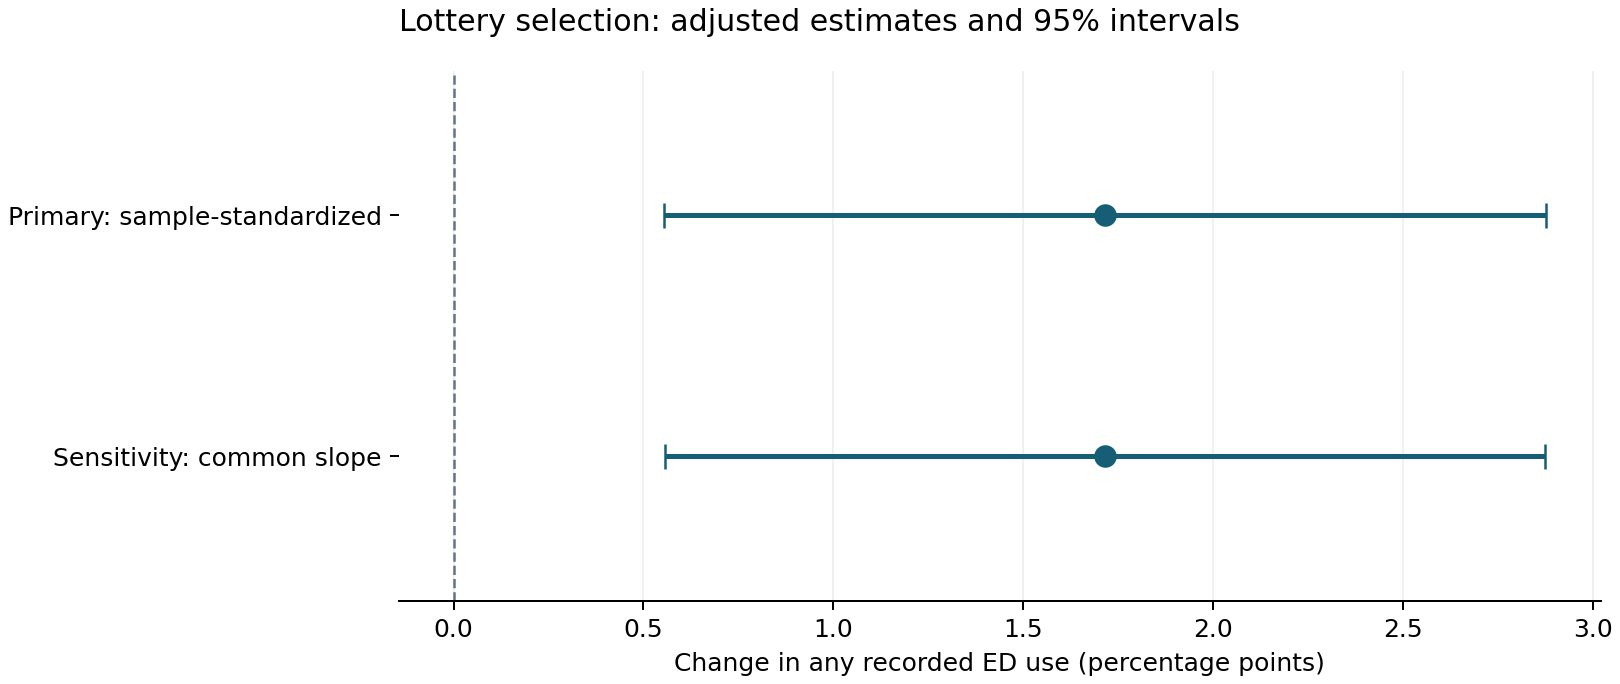

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
for position, (_, row) in zip([1, 0], results.iterrows()):
    ax.errorbar(
        row.effect_pp,
        position,
        xerr=[[row.effect_pp - row.ci_low_pp], [row.ci_high_pp - row.effect_pp]],
        fmt="o",
        color="#155e75",
        capsize=5,
        markersize=8,
        linewidth=2,
    )
ax.axvline(0, color="#64748b", linestyle="--", linewidth=1)
ax.set_yticks([1, 0], results.model)
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Change in any recorded ED use (percentage points)")
ax.set_title(
    "Lottery selection: adjusted estimates and 95% intervals", loc="left", pad=16
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.18)
fig.savefig("lottery_effect.png", dpi=180, facecolor="white")
plt.show()
plt.close(fig)


## 6. Conclusion and limits

Under the documented conditional lottery and sample-selection assumptions, selection produced a modest increase in the probability of recorded ED use. This is the effect of the **opportunity to apply**, not a Medicaid-enrollment effect.

An increase in use does not establish whether care was necessary, improved health, or increased net costs. This outcome alone does not support a recommendation to expand or contract Medicaid. Generalization is limited to this lottery population, catchment, hospital coverage, and calendar period. Public data cannot independently verify the original clinical linkage, and balance on observed characteristics does not establish all identifying assumptions.

**What this project demonstrates:** defining a causal estimand, distinguishing assignment from receipt, respecting household-level design, checking linked data, estimating interpretable uncertainty, and communicating a limited conclusion.

### Sources and reproducibility

- Finkelstein, Amy. *Oregon Health Insurance Experiment Public Use Data*, 2013. [Data and documentation](https://www.nber.org/research/data/oregon-health-insurance-experiment-data). Source archive includes user guide, codebooks, and Science replication files.
- Taubman et al. (2014), *Medicaid Increases Emergency-Department Use: Evidence from Oregon’s Health Insurance Experiment*. [Study](https://pmc.ncbi.nlm.nih.gov/articles/PMC3955206/) and [supplementary methods](https://economics.mit.edu/research/publications/appendices-medicaid-increases-emergencydepartment-use-evidence-oregons-health).
- [statsmodels clustered covariance documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.get_robustcov_results.html).

This notebook is a focused reanalysis, not a reproduction of every published result. The detailed Stage 1–3 notebooks in the working project preserve development and validation. `requirements.txt` records the numerical and plotting packages used here.

### Tableau companion

Open [OHIE_Dashboard_Verified.twbx](OHIE_Dashboard_Verified.twbx) for the interactive dashboard. Its effect plot uses synchronized axes: circles are estimated effects and horizontal lines span the Python-computed 95% confidence limits. Raw group rates remain explicitly descriptive. The workbook embeds aggregate data only.

This release was rerun using Python 3.12.7, NumPy 1.26.4, pandas 2.2.2, statsmodels 0.14.2, matplotlib 3.9.2, and patsy 0.5.6. The matching versions are recorded in requirements.txt. Results agree with the development analysis. A fresh dependency installation was not part of this release check.